# LSST

In [1]:
# Standard library
import warnings
from concurrent.futures import ThreadPoolExecutor, as_completed

# Third-party
import numpy as np
import sep
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from astropy.io import fits
from astropy.table import Table
from astropy.visualization import ZScaleInterval

from IPython.display import display
from tqdm.notebook import tqdm

# Rubin / LSST routines
try:
    from lsst.daf.butler import Butler
    import lsst.geom as geom
    import lsst.sphgeom as sphgeom
    from lsst.geom import Box2I, Point2I, Extent2I, Point2D
    from lsst.geom import SpherePoint, degrees
    from lsst.afw.image import ExposureF, LOCAL, PARENT
    from lsst.skymap import BaseSkyMap
    import lsst.afw.display as afw_display

    print("✓ LSST packages loaded successfully")
except ImportError as exc:
    raise ImportError(
        "Check the names and versions of imported packages." 
        "Warning: This pipeline only works inside the Rubin Science Platform"
    ) from exc

warnings.filterwarnings("ignore", category=RuntimeWarning)

✓ LSST packages loaded successfully


In [2]:
REPO         = "/repo/main"                # Butler repository URI
COLLECTION   = "LSSTComCam/DP1" # Butler collection — adjust for your RSP instance
SKYMAP_NAME  = "lsst_cells_v1"             # Sky map name used for DP1 coadds
CATALOG_PATH = "selected_cleaned.fits" 

#  Bands
BANDS = ["u", "g", "r", "i", "z", "y"]
#  Image parameters
PLATE_SCALE   = 0.2   # arcsec/pixel  (DP1 coadds)
HALF_SIZE     = 75    # cutout half-width in pixels  →  30" full stamp
FALLBACK_GAIN = 1.0   # used when the image header does not carry a gain keyword

#  Runtime
N_WORKERS = 1   # parallel threads — keep ≤ 4 on shared RSP nodes
ra, dec = 53.120100702454984, 27.73221164457574

In [3]:
cat = Table.read(CATALOG_PATH)

# Validate required columns
for col in ("RA", "DEC"):
    if col not in cat.colnames:
        raise ValueError(f"Required column '{col}' not found. Available: {cat.colnames}")

print(f"Catalog : {CATALOG_PATH}")
print(f"Sources : {len(cat):,}")
print(f"Columns : {cat.colnames}\n")
# max_rad=np.max(cat["rad"])
# half_size=int(10*max_rad)
# Show first rows as an interactive HTML table
display(cat[:10].to_pandas())

Catalog : selected_cleaned.fits
Sources : 6,276
Columns : ['id', 'RA', 'DEC', 'R_KRON', 'A', 'B', 'jwst.nircam.F090W', 'jwst.nircam.F090W_err', 'jwst.nircam.F115W', 'jwst.nircam.F115W_err', 'jwst.nircam.F150W', 'jwst.nircam.F150W_err', 'jwst.nircam.F182M', 'jwst.nircam.F182M_err', 'jwst.nircam.F200W', 'jwst.nircam.F200W_err', 'jwst.nircam.F210M', 'jwst.nircam.F210M_err', 'jwst.nircam.F277W', 'jwst.nircam.F277W_err', 'jwst.nircam.F335M', 'jwst.nircam.F335M_err', 'jwst.nircam.F356W', 'jwst.nircam.F356W_err', 'jwst.nircam.F410M', 'jwst.nircam.F410M_err', 'jwst.nircam.F430M', 'jwst.nircam.F430M_err', 'jwst.nircam.F444W', 'jwst.nircam.F444W_err', 'jwst.nircam.F460M', 'jwst.nircam.F460M_err', 'jwst.nircam.F480M', 'jwst.nircam.F480M_err', 'hst.acs.wfc.F435W', 'hst.acs.wfc.F435W_err', 'hst.acs.wfc.F606W', 'hst.acs.wfc.F606W_err', 'hst.acs.wfc.F775W', 'hst.acs.wfc.F775W_err', 'hst.acs.wfc.F814W', 'hst.acs.wfc.F814W_err', 'hst.wfc3.ir.F105W', 'hst.wfc3.ir.F105W_err', 'hst.wfc3.ir.F125W', 'hst.wf

,id,RA,DEC,R_KRON,A,B,jwst.nircam.F090W,jwst.nircam.F090W_err,jwst.nircam.F115W,jwst.nircam.F115W_err,...,rubin.lsst.i,rubin.lsst.i_err,rubin.lsst.z,rubin.lsst.z_err,rubin.lsst.y,rubin.lsst.y_err,F435mag,F435mag_err,miu_x_corr,miu_x_corr_err
0,840,53.115096,-27.920416,0.174520,0.063840,0.052210,0.000016,0.000002,0.000014,0.000002,...,-99.9,-99.9,-99.9,-99.9,-99.9,-99.9,29.445553,0.528505,26.568277,0.528505
1,1114,53.109820,-27.918129,0.207845,0.078490,0.061637,0.000012,0.000003,0.000018,0.000003,...,-99.9,-99.9,-99.9,-99.9,-99.9,-99.9,29.065488,0.532235,26.705343,0.532235
2,1116,53.109420,-27.918139,0.125768,0.058420,0.041354,0.000003,0.000002,0.000008,0.000001,...,-99.9,-99.9,-99.9,-99.9,-99.9,-99.9,30.671207,1.266817,27.495567,1.266817
3,1145,53.111852,-27.917858,0.200182,0.134970,0.066477,0.000028,0.000003,0.000029,0.000002,...,-99.9,-99.9,-99.9,-99.9,-99.9,-99.9,29.212361,0.519972,26.082428,0.519972
4,1146,53.119325,-27.917870,0.209145,0.161938,0.072298,0.000020,0.000006,0.000027,0.000006,...,-99.9,-99.9,-99.9,-99.9,-99.9,-99.9,29.460383,0.740438,26.500648,0.740438
5,1150,53.111576,-27.917860,0.113729,0.050629,0.036869,0.000004,0.000001,0.000003,0.000001,...,-99.9,-99.9,-99.9,-99.9,-99.9,-99.9,NaN,0.000000,NaN,0.000000
6,1165,53.109886,-27.917750,0.204683,0.094155,0.071716,0.000018,0.000003,0.000020,0.000002,...,-99.9,-99.9,-99.9,-99.9,-99.9,-99.9,34.942291,103.893557,32.944522,103.893557
7,1275,53.105054,-27.916888,0.404509,0.120272,0.105040,0.000025,0.000008,0.000046,0.000007,...,-99.9,-99.9,-99.9,-99.9,-99.9,-99.9,28.024449,0.550098,27.152040,0.550098
8,1326,53.104399,-27.916646,0.227948,0.126824,0.072794,0.000012,0.000004,0.000018,0.000003,...,-99.9,-99.9,-99.9,-99.9,-99.9,-99.9,29.836207,1.124951,27.226262,1.124951
9,1397,53.114557,-27.916275,0.114823,0.057701,0.052757,0.000008,0.000002,0.000011,0.000001,...,-99.9,-99.9,-99.9,-99.9,-99.9,-99.9,30.455212,0.797839,27.122755,0.797839


In [4]:
# print(f"Opening Butler : {REPO}")
# print(f"Collection     : {COLLECTION}")
# butler = dafButler.Butler(REPO, collections=[COLLECTION])
# skymap = butler.get("skyMap", skymap=SKYMAP_NAME)

butler = Butler("dp1", collections="LSSTComCam/DP1")
assert butler is not None

# skymap = butler.get("skyMap", skymap=SKYMAP_NAME)

print(f"✓ Butler ready")
# print(f"✓ Sky map '{SKYMAP_NAME}' loaded")
afw_display.setDefaultBackend('matplotlib')

✓ Butler ready


In [5]:
def extract_cutout(dataset_refs, ra: float, dec: float, half_size: int):
    """
    Cut a (2*half_size+1) x (2*half_size+1) stamp centred on RA, Dec input.
    Returns (img_array, var_array, x_src_in_stamp, y_src_in_stamp) or None.
    """

    coadd=butler.get(dataset_refs[0])
    wcs = coadd.getWcs()
    if wcs is None:
        print(f"Flag: probably and overlap region, check {ra}, {dec} again")
        return None
    
    coord = SpherePoint(ra * degrees, dec * degrees)
    pixel_point = wcs.skyToPixel(coord)
    px, py = pixel_point.getX(), pixel_point.getY()

    bbox = Box2I(Point2I(int(px - half_size), int(py - half_size)),
                 Extent2I(2*half_size, 2*half_size))

    if not coadd.getBBox().contains(bbox):
        print(f" Cutout around RA={ra}, Dec={dec} is out of image bounds, switch to next ref.")
        print(f"Length of dataset_refs= {len(dataset_refs)}")
    # continue

    cutout = coadd[bbox]

    # bbox = exposure.getBBox()
    # if not bbox.contains(geom.Point2I(int(px), int(py))):
    #     return None

    x0c = max(int(round(px)) - half_size, bbox.getMinX())
    y0c = max(int(round(py)) - half_size, bbox.getMinY())
    x1c = min(int(round(px)) + half_size, bbox.getMaxX())
    y1c = min(int(round(py)) + half_size, bbox.getMaxY())

    # subexp = exposure.Factory(
    #     exposure,
    #     geom.Box2I(geom.Point2I(x0c, y0c), geom.Point2I(x1c, y1c)),
    # )
    # img = subexp.image.array.astype(np.float64)
    # var = subexp.variance.array.astype(np.float64)

    img=cutout.getImage()
    var=cutout.getVariance()
    bad = ~np.isfinite(img.array) | ~np.isfinite(var.array)
    img.array[bad] = 0.0
    var.array[bad] = 0.0
    photo_calib = cutout.getPhotoCalib()  # photometric calibration object
    flux_mag0 = photo_calib.getInstFluxAtZeroMagnitude()
    zp = 2.5 * np.log10(flux_mag0)

    return img, var, px - x0c, py - y0c, zp

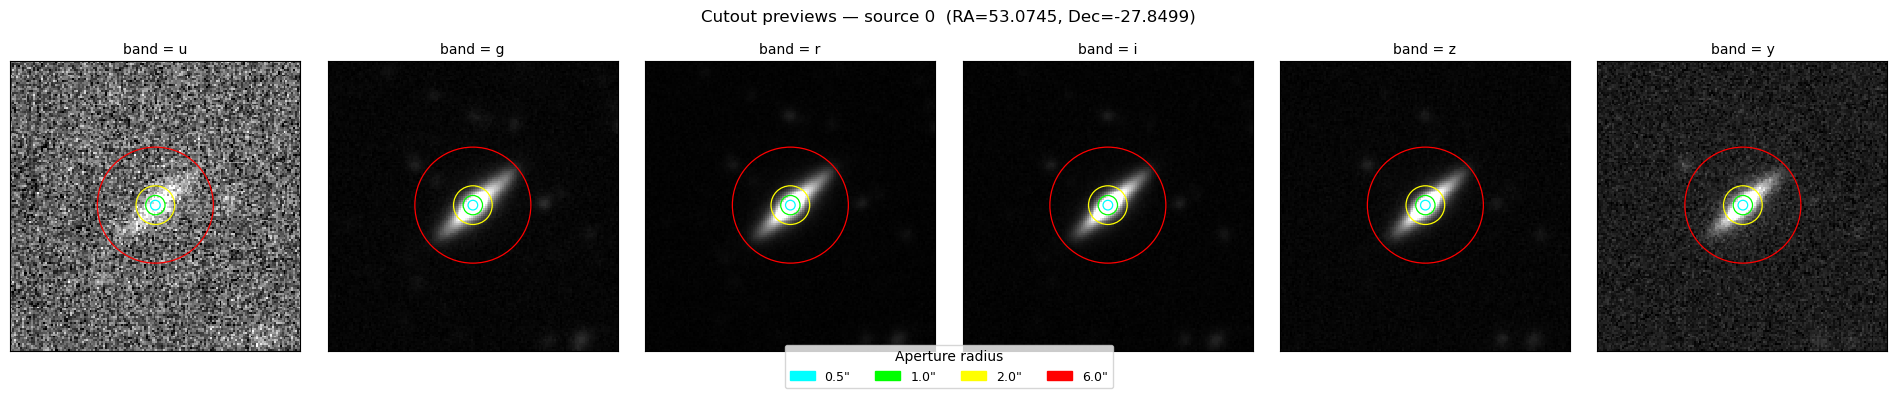

In [9]:
# Test overlap check on first source
test_id = 4141 # third most massive galaxy
test_ra  = float(cat["RA"][test_id])
test_dec = float(cat["DEC"][test_id])

# Subset of radii to draw (avoids clutter)
preview_radii_arcsec = [0.5, 1.0, 2.0, 6.0]
preview_radii_px     = [r / PLATE_SCALE for r in preview_radii_arcsec]
ap_colors            = ["cyan", "lime", "yellow", "red"]

fig, axes = plt.subplots(1, len(BANDS), figsize=(3.2 * len(BANDS), 3.5))
fig.suptitle(
    f'Cutout previews — source 0  (RA={test_ra:.4f}, Dec={test_dec:.4f})',
    fontsize=12, y=1.02,
)

hdus = [fits.PrimaryHDU()]

for ax, band in zip(axes, BANDS):
    ax.set_title(f"band = {band}", fontsize=10)
    # exposure = load_coadd_patch(band, tract, patch)
    query = """band.name = '{}' AND patch.region OVERLAPS POINT({}, {})
        """.format(band, test_ra, test_dec)
    # dataset_check = butler.find_dataset("deep_coadd", data_id=data_id)
    dataset_refs = butler.query_datasets("deep_coadd", where=query)


    if len(dataset_refs)==0:
        ax.text(0.5, 0.5, "No data", ha="center", va="center", transform=ax.transAxes)
        ax.axis("off")
        continue

    result = extract_cutout(dataset_refs, test_ra, test_dec, HALF_SIZE)
    if result is None:
        ax.text(0.5, 0.5, "Outside patch", ha="center", va="center", transform=ax.transAxes)
        ax.axis("off")
        continue

    img, var, x_src, y_src, zp = result

    hdu = fits.ImageHDU(data=img.array, name=f"IMAGE_{band}")
    hdus.append(hdu)
    
    vmin = np.nanpercentile(img.array, 1.0)
    vmax = np.nanpercentile(img.array, 99.5)
    ax.imshow(img.array, origin="lower", cmap="gray", vmin=vmin, vmax=vmax, interpolation="nearest")
    # ax.plot(x_src, y_src, "+", color="white", ms=8, mew=1.5)

    for r_px, col in zip(preview_radii_px, ap_colors):
        ax.add_patch(plt.Circle((x_src, y_src), r_px, fill=False, color=col, lw=0.9))

    ax.set_xticks([]); ax.set_yticks([])


hdul = fits.HDUList(hdus)

hdul.writeto("galaxy_images.fits", overwrite=True)

# Aperture legend
legend_patches = [
    mpatches.Patch(color=col, label=f'{r}"')
    for r, col in zip(preview_radii_arcsec, ap_colors)
]
fig.legend(
    handles=legend_patches, loc="lower center",
    ncol=4, fontsize=9, title="Aperture radius",
    bbox_to_anchor=(0.5, -0.08),
)
plt.tight_layout()
plt.show()

# JWST